In [4]:
import sys
import os
from typing import NamedTuple
import math
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

from sklearn.model_selection import TimeSeriesSplit, StratifiedKFold
import jax
import jax.numpy as jnp
import optax


from utils import read_utils
from utils import plot_utils
from utils import train_utils

sys.path.append(os.path.join(os.getcwd(), '../../'))
from models import bom
from models import hgm

In [5]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)
importlib.reload(bom)
importlib.reload(hgm)

<module 'models.hgm' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/organisms/mouse-2019-stringer/../../models/hgm.py'>

In [6]:
default_hyperparameters = {
	'dimensions': 1,
	'loss1_lambda': 0.0,
	'loss2_lambda': 1.0 - 0.0,
	'w1_reg_lambda': 0.0,
	'w2_reg_lambda': 0.0,
}

# Functions

In [4]:
class Lambdas(NamedTuple):
	loss_lambdas: tuple[float, float]
	reg_lambdas: tuple[float, float]
	cca_lambdas: tuple[float, float]

In [5]:
def separate_losses(file_ids, columns, models_spn_man_rec_res_pres):
	models_spn = [
		[
			pd.DataFrame(data=np.array(split[0])[None], columns=columns[i]) for split in models_spn_man_rec_res_pres[i]
		] for i in range(len(file_ids))
	]
	models_man = [
		[
			pd.DataFrame(data=np.array(split[1]), columns=[f'M{i}' for i in range(np.array(split[1]).shape[1])]) for split in models_spn_man_rec_res_pres[i]
		] for i in range(len(file_ids))
	]
	(models_rec,
	 models_res,
	 models_pres) = tuple(
		[
			[
				pd.DataFrame(data=np.array(split[m]), columns=columns[i]) for split in models_spn_man_rec_res_pres[i]
			] for i in range(len(file_ids))
		] for m in [2, 3, 4]
	)
	return models_spn, models_man, models_rec, models_res, models_pres

In [6]:
def assemble(boms_scores_per_neuron, hgms_scores_per_neuron):
	neurons_labels = [scores_per_neuron[0].columns for scores_per_neuron in hgms_scores_per_neuron]

	boms_scores_per_neuron = [np.array([split.values[0] for split in scores]) for scores in boms_scores_per_neuron]
	hgms_scores_per_neuron = [np.array([split.values[0] for split in scores]) for scores in hgms_scores_per_neuron]

	neuron_scores = dict()
	boms_scores_per_neuron_avg = [np.mean(scores, axis=0) for scores in boms_scores_per_neuron]
	hgms_scores_per_neuron_avg = [np.mean(scores, axis=0) for scores in hgms_scores_per_neuron]
	for label_list, score_bom_list, score_hgm_list in zip(neurons_labels, boms_scores_per_neuron_avg, hgms_scores_per_neuron_avg):
		for i in range(len(label_list)):
			label = label_list[i]
			if label != '' and str(label)[-1] != '_':
				score_bom_new, score_hgm_new = np.array(score_bom_list[i]), np.array(score_hgm_list[i])
				if len(score_hgm_new.shape) == 0:
					score_bom_new = score_bom_new.reshape(1, 1)
					score_hgm_new = score_hgm_new.reshape(1, 1)
				if label not in neuron_scores.keys():
					neuron_scores[label] = (score_bom_new, score_hgm_new)
				else:
					score_bom_prev, score_hgm_prev = neuron_scores[label]
					neuron_scores[label] = (np.vstack([score_bom_prev, score_bom_new]), np.vstack([score_hgm_prev, score_hgm_new]))

	return neuron_scores

# read & prep

In [7]:
bom_reg_lamdas = {
	# 'w1_reg_lambda': default_hyperparameters['w1_reg_lambda'],
	'w1_reg_lambda': 2.8E-02,  #1E-2,
}
hgm_reg_lamdas = {
	# 'w1_reg_lambda': default_hyperparameters['w1_reg_lambda'],
	# 'w2_reg_lambda': default_hyperparameters['w2_reg_lambda'],
	'w1_reg_lambda': 4.4E-03,  #3E-3,
	'w2_reg_lambda': 5.6E-07,  #1E-7,
}


selection_t = 2000
selection_n = 4
selection_bhl = ['running_speed', 'pupil_area']  # whisking?


npx = True
# read_ids = list(range(0, 8+1))
read_ids = [3]
plot_id = 3

In [8]:
path = os.path.join(read_utils.get_data_path(), 'mouse-2019-stringer/6163622/sessions')

(file_ids, filenames,
 traces,
 continuous_behaviors,
 motion_pcs,
 motion_masks) = read_utils.get_data(path, read_ids, with_whisking=True)

# read models

In [9]:
prefix = ''

In [10]:
if npx:
	bom_load_name = os.path.join(prefix, f'bom_w1-{bom_reg_lamdas['w1_reg_lambda']:.0E}')
	hgm_load_name = os.path.join(prefix, f'hgm_w1-{hgm_reg_lamdas['w1_reg_lambda']:.0E}_w2-{hgm_reg_lamdas['w2_reg_lambda']:.0E}')

In [11]:
if npx:
	boms_params = train_utils.load_params(bom_load_name, filenames)

	boms_losses_all = train_utils.load_losses(bom_load_name, filenames)
	boms_losses_train = [losses[0] for losses in boms_losses_all]
	boms_man_losses_train = [losses[1] for losses in boms_losses_all]
	boms_res_losses_train = [losses[2] for losses in boms_losses_all]
	boms_mpe_losses_train = [losses[3] for losses in boms_losses_all]
	boms_losses = [losses[4] for losses in boms_losses_all]
	boms_man_losses = [losses[5] for losses in boms_losses_all]
	boms_res_losses = [losses[6] for losses in boms_losses_all]
	boms_mpe_losses = [losses[7] for losses in boms_losses_all]

	hgms_params = train_utils.load_params(hgm_load_name, filenames)

	hgms_losses_all = train_utils.load_losses(hgm_load_name, filenames)
	hgms_losses_train = [losses[0] for losses in hgms_losses_all]
	hgms_man_losses_train = [losses[1] for losses in hgms_losses_all]
	hgms_res_losses_train = [losses[2] for losses in hgms_losses_all]
	hgms_mpe_losses_train = [losses[3] for losses in hgms_losses_all]
	hgms_losses = [losses[4] for losses in hgms_losses_all]
	hgms_man_losses = [losses[5] for losses in hgms_losses_all]
	hgms_res_losses = [losses[6] for losses in hgms_losses_all]
	hgms_mpe_losses = [losses[7] for losses in hgms_losses_all]

 # npx

### losses

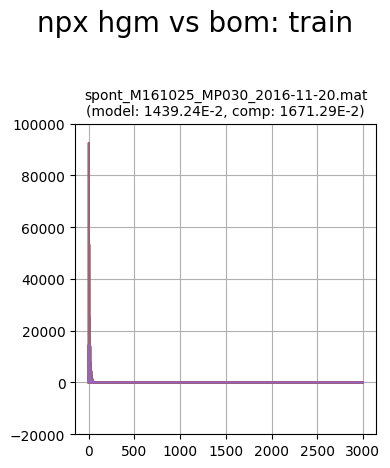

In [12]:
if npx:
	plot_utils.plot_losses_splits('npx hgm vs bom: train',
								  filenames,
								  hgms_losses_train, boms_losses_train,
								  ylimits=None)

In [13]:
# if npx:
# 	plot_utils.plot_losses_splits('npx hgm vs bom: man train',
# 								  filenames,
# 								  hgms_man_losses_train, boms_man_losses_train,
# 								  ylimits=None)

In [14]:
# if npx:
# 	plot_utils.plot_losses_splits('npx hgm vs bom: res train',
# 								  filenames,
# 								  hgms_res_losses_train, boms_res_losses_train,
# 								  ylimits=None)

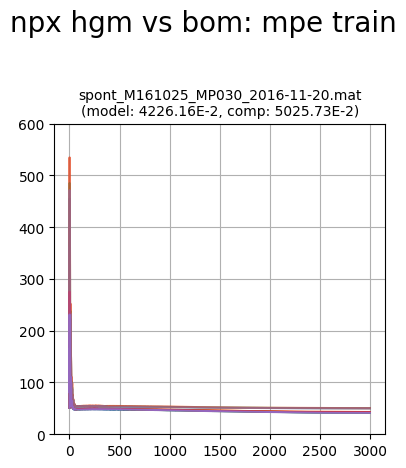

In [15]:
if npx:
	plot_utils.plot_losses_splits('npx hgm vs bom: mpe train',
								  filenames,
								  hgms_mpe_losses_train, boms_mpe_losses_train)

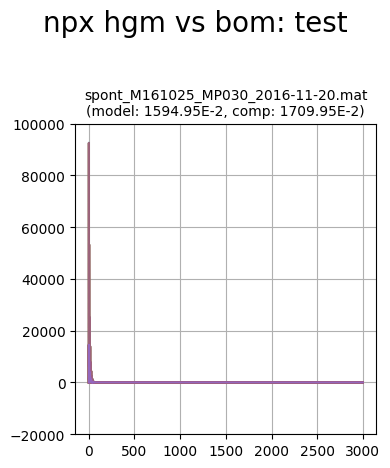

In [16]:
if npx:
	plot_utils.plot_losses_splits('npx hgm vs bom: test',
								  filenames,
								  hgms_losses, boms_losses,
								  ylimits=None)

In [17]:
# if npx:
# 	plot_utils.plot_losses_splits('npx hgm vs bom: man test',
# 								  filenames,
# 								  hgms_man_losses, boms_man_losses,
# 								  ylimits=None)

In [18]:
# if npx:
# 	plot_utils.plot_losses_splits('npx hgm vs bom: res test',
# 								  filenames,
# 								  hgms_res_losses, boms_res_losses,
# 								  ylimits=None)

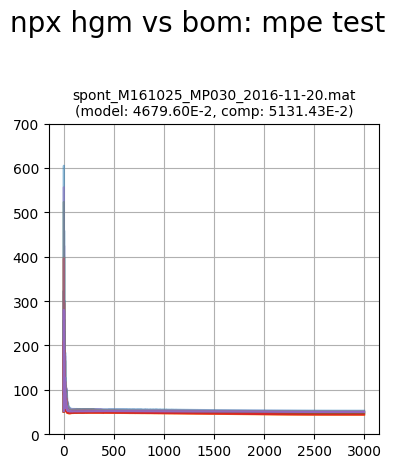

In [19]:
if npx:
	plot_utils.plot_losses_splits('npx hgm vs bom: mpe test',
								  filenames,
								  hgms_mpe_losses, boms_mpe_losses)

### predict & score

In [20]:
if npx:
	splits = list()
	for id in file_ids:
		# splitting
		behavior = continuous_behaviors[file_ids.index(id)][['running_speed']].values
		classes = behavior > np.quantile(behavior, 0.05)
		s = list(StratifiedKFold(n_splits=5, shuffle=False).split(np.zeros(traces[file_ids.index(id)].shape[0]), classes))
		splits.append(s)

In [22]:
if npx:
	boms_spn_man_rec_res_pres = [[
		bom.score_fn(params, traces[i].values[eval], motion_pcs[i][0].values[eval]) for params, (train, eval) in zip(boms_params[i], splits[i])
	] for i in range(len(file_ids))]

	hgms_spn_man_rec_res_pres = [[
		hgm.score_fn(params, traces[i].values[eval], motion_pcs[i][0].values[eval]) for params, (train, eval) in zip(hgms_params[i], splits[i])
	] for i in range(len(file_ids))]

	(boms_spn,
	 boms_man,
	 boms_rec,
	 boms_res,
	 boms_pres) = separate_losses(file_ids, [trace.columns for trace in traces], boms_spn_man_rec_res_pres)

	(hgms_spn,
	 hgms_man,
	 hgms_rec,
	 hgms_res,
	 hgms_pres) = separate_losses(file_ids, [trace.columns for trace in traces], hgms_spn_man_rec_res_pres)

### performance

In [23]:
if npx:
	neuron_scores = assemble(boms_spn, hgms_spn)

In [27]:
neuron_scores = dict(
    reversed(sorted(list(neuron_scores.items())[:100], key=lambda item: item[1][1]))
)

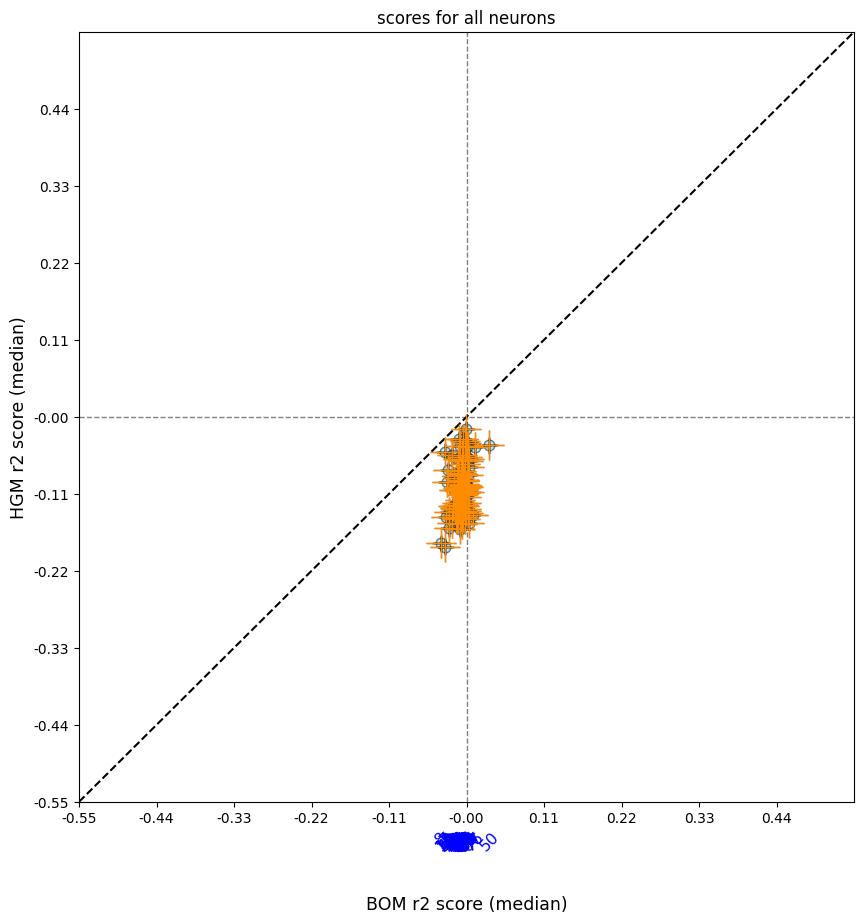

In [28]:
if npx:
	plot_utils.plot_performance_plot(neuron_scores, None,
									 title='scores for all neurons', limits=(-0.55, 0.55, -0.55, 0.55))

### traces

In [ ]:
if npx:
	boms_spn_man_rec_res_pres = [[
		bom.score_fn(params, traces[i].values, motion_pcs[i][0].values) for params in boms_params[i]
	] for i in range(len(file_ids))]

	hgms_spn_man_rec_res_pres = [[
		hgm.score_fn(params, traces[i].values, motion_pcs[i][0].values) for params in hgms_params[i]
	] for i in range(len(file_ids))]

	(boms_spn_full,
	 boms_man_full,
	 boms_rec_full,
	 boms_res_full,
	 boms_pres_full) = separate_losses(file_ids, [trace.columns for trace in traces], boms_spn_man_rec_res_pres)

	(hgms_spn_full,
	 hgms_man_full,
	 hgms_rec_full,
	 hgms_res_full,
	 hgms_pres_full) = separate_losses(file_ids, [trace.columns for trace in traces], hgms_spn_man_rec_res_pres)

In [ ]:
# if npx:
# 	_, _, traces_cca_rec, _, _, _, _, _ = train_utils.get_manifolds_cca(traces, continuous_behaviors, n_cv=default_hyperparameters['dimensions'], n_pc=0)
# 	traces_cca_res = [pd.DataFrame(data=trace.values - trace_cca_rec.values, columns=trace.columns) for trace, trace_cca_rec in zip(traces, traces_cca_rec)]

In [ ]:
if npx:
	splits = 5
	plot_utils.plot_traces_x_splits(
		f'{filenames[file_ids.index(plot_id)]} npx hgm & bom definitions manifold',
		continuous_behaviors[file_ids.index(plot_id)][['running_speed']],
		traces[file_ids.index(plot_id)].iloc[2000, :5],
		[hgms_rec_full[file_ids.index(plot_id)][i].iloc[2000, :5] for i in range(splits)],
		[boms_rec_full[file_ids.index(plot_id)][i].iloc[2000, :5] for i in range(splits)],
		plot_first=True, plots_per_row=1, ylimits=None,
		save_name=None)  #'GCAMP_MAN'

In [ ]:
if npx:
	splits = 5
	plot_utils.plot_traces_x_splits(
		f'{filenames[file_ids.index(plot_id)]} npx hgm & bom definitions residuals',
		continuous_behaviors[file_ids.index(plot_id)][['running_speed']],
		traces[file_ids.index(plot_id)].iloc[2000, :5],
		[hgms_res_full[file_ids.index(plot_id)][i].iloc[2000, :5] for i in range(splits)],
		[boms_res_full[file_ids.index(plot_id)][i].iloc[2000, :5] for i in range(splits)],
		plot_first=True, plots_per_row=1, ylimits=(-0.5, 0.5),
		save_name=None)  #'GCAMP_RES'

In [ ]:
if npx:
	for i in range(5):
		plot_utils.plot_traces_comparisons(
			f'{filenames[file_ids.index(plot_id)]} split {i} npx hgm & bom predictions residuals',
			continuous_behaviors[file_ids.index(plot_id)][['running_speed']],
			traces[file_ids.index(plot_id)].iloc[2000, :5],
			[hgms_res_full[file_ids.index(plot_id)][i].iloc[2000, :5],
			 hgms_pres_full[file_ids.index(plot_id)][i].iloc[2000, :5]],
			[boms_res_full[file_ids.index(plot_id)][i].iloc[2000, :5],
			 boms_pres_full[file_ids.index(plot_id)][i].iloc[2000, :5]],
			plot_first=True, plots_per_row=1, ylimits=(-0.5, 0.5),
			save_name=None)  #f'GCAMP_PRES_S{i}'